## 1. Forecasting Dataset Preparation

The forecasting problem is defined as an hourly demand prediction:

- **Target variable:** `cnt` (total hourly bike rentals)
- **Observation frequency:** Hourly
- **Prediction objective:** Estimate hourly bike-sharing demand using relevant temporal and env features.

Two variables, `casual` and `registered`, will be excluded from the predictive feature set.

The original dataset will remain unchanged. A separate modeling dataset will be created for subsequent feature engineering and forecasting experiments.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid")

data_path = Path("hour.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "hour.csv could not be found."
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully.
Dataset shape: (17379, 17)


In [2]:
df_model = df.copy()

df_model["datetime"] = (
    pd.to_datetime(df_model["dteday"])
    + pd.to_timedelta(df_model["hr"], unit="h")
)

df_model = (
    df_model
    .sort_values("datetime")
    .reset_index(drop=True)
)

assert df_model["cnt"].notna().all(), "Missing target values detected."
assert df_model["datetime"].notna().all(), "Invalid timestamps detected."
assert df_model["datetime"].is_monotonic_increasing

# Check duplicate timestamps
duplicate_count = df_model["datetime"].duplicated().sum()

# Check missing timestamps
expected_range = pd.date_range(
    start=df_model["datetime"].min(),
    end=df_model["datetime"].max(),
    freq="h"
)

missing_timestamps = len(
    expected_range.difference(df_model["datetime"])
)

validation_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Unique Timestamps",
        "Duplicate Timestamps",
        "Missing Timestamps",
        "Target Missing Values",
        "Chronological Ordering"
    ],
    "Value": [
        len(df_model),
        df_model["datetime"].nunique(),
        duplicate_count,
        missing_timestamps,
        df_model["cnt"].isna().sum(),
        df_model["datetime"].is_monotonic_increasing
    ]
})

display(validation_summary)

,Metric,Value
0,Total Observations,17379
1,Unique Timestamps,17379
2,Duplicate Timestamps,0
3,Missing Timestamps,165
4,Target Missing Values,0
5,Chronological Ordering,True


## 2. Feature Engineering

Feature engineering is performed to capture temporal patterns and conditions that may influence hourly bike-sharing demand.

**Temporal Features**
- Hour of the day
- Day of the week
- Month
- Weekend indicator
- Working-day indicator
- Seasonal information

**Cyclical Features**

Hour, weekday, and month variables will also be represented through sine and cosine transformations.

**Weather Features**

Temperature, apparent temperature, humidity, wind speed, and weather conditions will be retained as potential explanatory variables.

The target variable will remain `cnt`. Variables representing completed rental transactions (`casual` and `registered`) and record identifiers will not be included as predictive features.

In [3]:
df_model["hour"] = df_model["datetime"].dt.hour
df_model["day_of_week"] = df_model["datetime"].dt.dayofweek
df_model["month"] = df_model["datetime"].dt.month

df_model["is_weekend"] = (
    df_model["day_of_week"] >= 5
).astype(int)

df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["hour"] / 24
)

df_model["weekday_sin"] = np.sin(
    2 * np.pi * df_model["day_of_week"] / 7
)

df_model["weekday_cos"] = np.cos(
    2 * np.pi * df_model["day_of_week"] / 7
)

df_model["month_sin"] = np.sin(
    2 * np.pi * (df_model["month"] - 1) / 12
)

df_model["month_cos"] = np.cos(
    2 * np.pi * (df_model["month"] - 1) / 12
)

display(
    df_model[
        [
            "datetime",
            "hour",
            "day_of_week",
            "month",
            "is_weekend",
            "hour_sin",
            "hour_cos",
            "weekday_sin",
            "weekday_cos",
            "month_sin",
            "month_cos"
        ]
    ].head(10)
)

,datetime,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos
0,2011-01-01 00:00:00,0,5,1,1,0.000,1.000,-0.975,-0.223,0.000,1.000
1,2011-01-01 01:00:00,1,5,1,1,0.259,0.966,-0.975,-0.223,0.000,1.000
2,2011-01-01 02:00:00,2,5,1,1,0.500,0.866,-0.975,-0.223,0.000,1.000
3,2011-01-01 03:00:00,3,5,1,1,0.707,0.707,-0.975,-0.223,0.000,1.000
4,2011-01-01 04:00:00,4,5,1,1,0.866,0.500,-0.975,-0.223,0.000,1.000
5,2011-01-01 05:00:00,5,5,1,1,0.966,0.259,-0.975,-0.223,0.000,1.000
6,2011-01-01 06:00:00,6,5,1,1,1.000,0.000,-0.975,-0.223,0.000,1.000
7,2011-01-01 07:00:00,7,5,1,1,0.966,-0.259,-0.975,-0.223,0.000,1.000
8,2011-01-01 08:00:00,8,5,1,1,0.866,-0.500,-0.975,-0.223,0.000,1.000
9,2011-01-01 09:00:00,9,5,1,1,0.707,-0.707,-0.975,-0.223,0.000,1.000


In [4]:
target = "cnt"

feature_columns = [
    "season",
    "yr",
    "holiday",
    "workingday",
    "weathersit",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

X = df_model[feature_columns].copy()
y = df_model[target].copy()

feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Data Type": X.dtypes.astype(str).values,
    "Missing Values": X.isna().sum().values,
    "Unique Values": X.nunique().values
})

display(feature_summary)

print(f"\nNumber of predictive features: {X.shape[1]}")
print(f"Number of observations: {len(X)}")
print(f"Target variable: {target}")

assert "casual" not in X.columns
assert "registered" not in X.columns
assert "cnt" not in X.columns
assert "instant" not in X.columns

,Feature,Data Type,Missing Values,Unique Values
0,season,int64,0,4
1,yr,int64,0,2
2,holiday,int64,0,2
3,workingday,int64,0,2
4,weathersit,int64,0,4
5,hour_sin,float64,0,21
6,hour_cos,float64,0,22
7,weekday_sin,float64,0,7
8,weekday_cos,float64,0,7
9,month_sin,float64,0,11



Number of predictive features: 16
Number of observations: 17379
Target variable: cnt


## 3. Chronological Train, Validation, and Test Split

Random splitting could allow future observations to influence model development, resulting in an unrealistic evaluation of forecasting performance.

The dataset will be divided into three sequential subsets:

- **Training set (70%)** 
- **Validation set (15%)**
- **Test set (15%)**

Consequently, each observation will retain its original position in the chronological sequence.

In [5]:
train_ratio = 0.70
validation_ratio = 0.15

n = len(df_model)

train_end = int(n * train_ratio)
validation_end = int(
    n * (train_ratio + validation_ratio)
)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:validation_end].copy()
X_test = X.iloc[validation_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:validation_end].copy()
y_test = y.iloc[validation_end:].copy()

train_dates = df_model["datetime"].iloc[:train_end]
val_dates = df_model["datetime"].iloc[train_end:validation_end]
test_dates = df_model["datetime"].iloc[validation_end:]

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Observations": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Start Date": [
        train_dates.min(),
        val_dates.min(),
        test_dates.min()
    ],
    "End Date": [
        train_dates.max(),
        val_dates.max(),
        test_dates.max()
    ],
    "Percentage": [
        len(X_train) / n * 100,
        len(X_val) / n * 100,
        len(X_test) / n * 100
    ]
})

display(split_summary)

assert train_dates.max() < val_dates.min()
assert val_dates.max() < test_dates.min()

,Dataset,Observations,Start Date,End Date,Percentage
0,Training,12165,2011-01-01 00:00:00,2012-05-27 01:00:00,69.998
1,Validation,2607,2012-05-27 02:00:00,2012-09-12 16:00:00,15.001
2,Test,2607,2012-09-12 17:00:00,2012-12-31 23:00:00,15.001


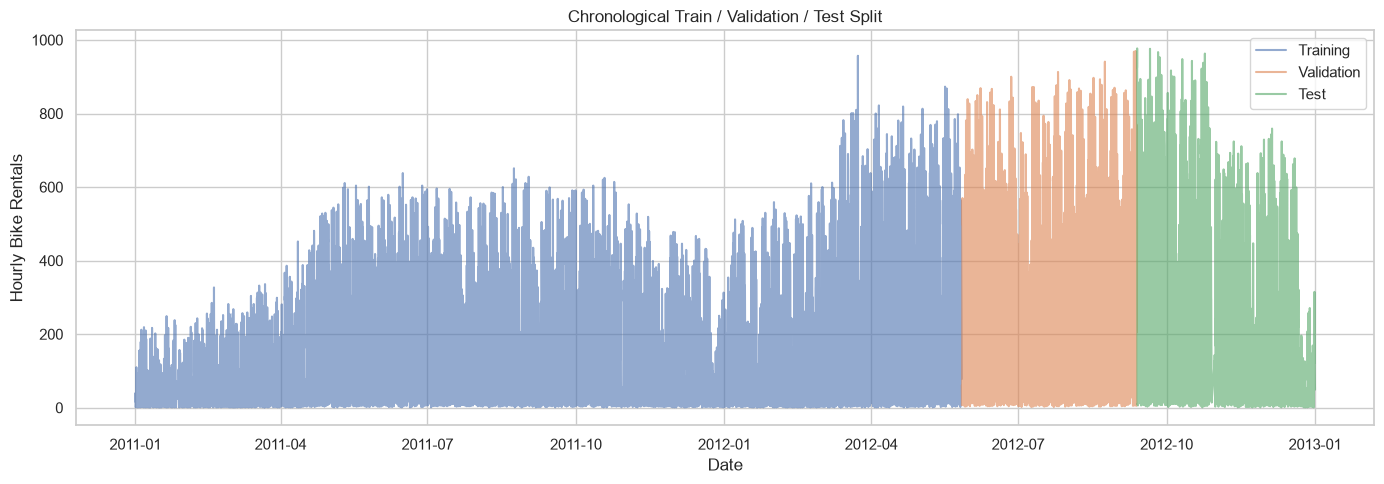

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    train_dates,
    y_train,
    label="Training",
    alpha=0.6
)

plt.plot(
    val_dates,
    y_val,
    label="Validation",
    alpha=0.6
)

plt.plot(
    test_dates,
    y_test,
    label="Test",
    alpha=0.6
)

plt.title("Chronological Train / Validation / Test Split")
plt.xlabel("Date")
plt.ylabel("Hourly Bike Rentals")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Baseline Forecasting Models

Baseline models establish a reference point against which more advanced forecasting approaches can be evaluated.

Two baseline strategies will be implemented:

1. **Global Mean Baseline:** Uses the average hourly demand observed in the training dataset as the prediction for every future observation.
2. **Hourly-Weekly Average Baseline:** Uses the historical average demand for each specific hour of the week, capturing recurring daily and weekly demand patterns.

All baseline statistics will be calculated exclusively from the training dataset to prevent information leakage.

In [7]:
global_mean = y_train.mean()

baseline_global = np.full(
    shape=len(y_val),
    fill_value=global_mean
)

train_hour_week = (
    df_model.loc[X_train.index, "day_of_week"] * 24
    + df_model.loc[X_train.index, "hour"]
)

val_hour_week = (
    df_model.loc[X_val.index, "day_of_week"] * 24
    + df_model.loc[X_val.index, "hour"]
)

hour_week_profile = (
    pd.DataFrame({
        "hour_week": train_hour_week,
        "demand": y_train
    })
    .groupby("hour_week")["demand"]
    .mean()
)

baseline_hour_week = (
    val_hour_week
    .map(hour_week_profile)
    .fillna(global_mean)
    .to_numpy()
)

print(f"Global mean: {global_mean:.2f}")
print(f"Weekly profile groups: {len(hour_week_profile)}")
print(f"Missing profile matches: {val_hour_week.map(hour_week_profile).isna().sum()}")

Global mean: 159.93
Weekly profile groups: 168
Missing profile matches: 0


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred, model_name):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )
    r2 = r2_score(y_true, y_pred)
    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
    ) * 100

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE (%)": wape
    }


baseline_results = []

baseline_results.append(
    evaluate_model(
        y_val,
        baseline_global,
        "Global Mean"
    )
)

baseline_results.append(
    evaluate_model(
        y_val,
        baseline_hour_week,
        "Hourly-Weekly Average"
    )
)

baseline_comparison = (
    pd.DataFrame(baseline_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(baseline_comparison.round(3))

,Model,MAE,RMSE,R2,WAPE (%)
0,Hourly-Weekly Average,127.046,168.459,0.431,45.205
1,Global Mean,194.135,253.970,-0.294,69.077


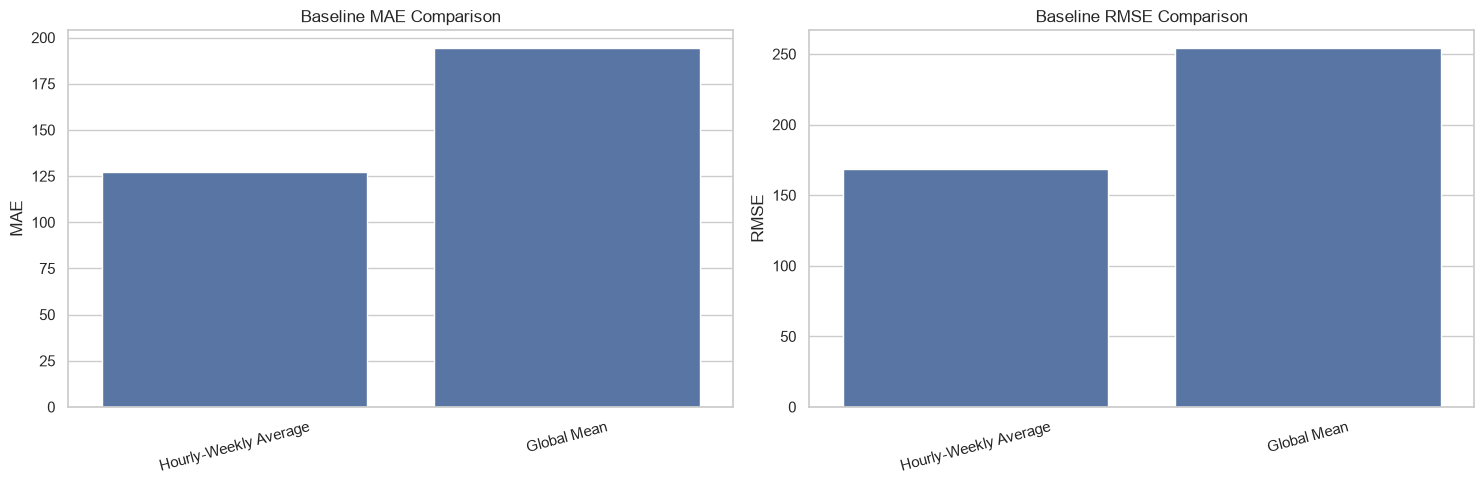

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MAE
sns.barplot(
    data=baseline_comparison,
    x="Model",
    y="MAE",
    ax=axes[0]
)

axes[0].set_title("Baseline MAE Comparison")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

# RMSE
sns.barplot(
    data=baseline_comparison,
    x="Model",
    y="RMSE",
    ax=axes[1]
)

axes[1].set_title("Baseline RMSE Comparison")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 5. Baseline Model Evaluation and Interpretation

The Global Mean model achieved an MAE of 194.14 and an R² of -0.294, indicating that a single average demand estimate is insufficient to represent the substantial variation in hourly rentals.

In contrast, the Hourly-Weekly Average model achieved:

- MAE: 127.05
- RMSE: 168.46
- R²: 0.431
- WAPE: 45.21%

This represents an approximately 34.6% reduction in MAE compared with the Global Mean baseline.

The improvement demonstrates that demand patterns differ considerably across hours and days of the week. Incorporating recurring temporal behavior therefore provides a substantially stronger forecasting benchmark.

However, the remaining prediction error indicates that temporal averages alone cannot fully explain demand fluctuations.

The next stage will investigate whether regression-based and machine learning models can improve forecasting accuracy by incorporating additional temporal and environmental features.

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = [
    "season",
    "yr",
    "holiday",
    "workingday",
    "weathersit"
]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

linear_regression_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

Numerical features: 11
Categorical features: 5


In [11]:
linear_regression_pipeline.fit(
    X_train,
    y_train
)

y_pred_lr = linear_regression_pipeline.predict(X_val)
print(f"Validation predictions: {len(y_pred_lr)}")
print(f"Minimum prediction: {y_pred_lr.min():.2f}")
print(f"Maximum prediction: {y_pred_lr.max():.2f}")
print(f"Negative predictions: {(y_pred_lr < 0).sum()}")

Validation predictions: 2607
Minimum prediction: 70.29
Maximum prediction: 467.26
Negative predictions: 0


In [12]:
lr_results = evaluate_model(
    y_val,
    y_pred_lr,
    "Linear Regression"
)

model_comparison = pd.concat(
    [
        baseline_comparison,
        pd.DataFrame([lr_results])
    ],
    ignore_index=True
)

model_comparison = (
    model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(model_comparison.round(3))

,Model,MAE,RMSE,R2,WAPE (%)
0,Hourly-Weekly Average,127.046,168.459,0.431,45.205
1,Linear Regression,136.323,174.391,0.390,48.506
2,Global Mean,194.135,253.970,-0.294,69.077


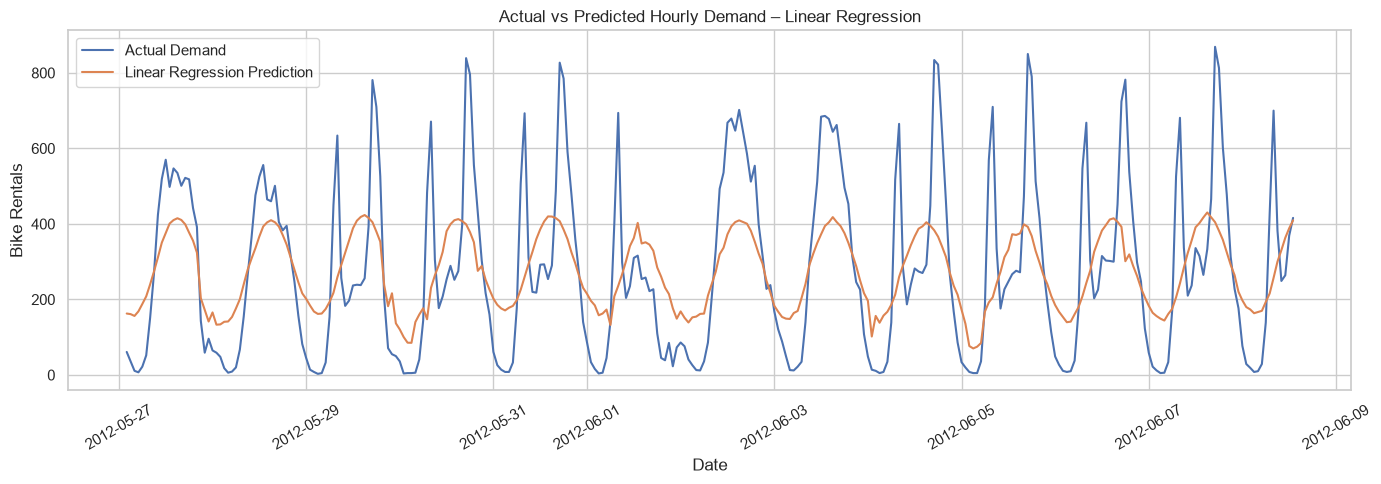

In [13]:
plt.figure(figsize=(14, 5))

sample_size = min(300, len(y_val))

plt.plot(
    val_dates.iloc[:sample_size],
    y_val.iloc[:sample_size].values,
    label="Actual Demand",
    linewidth=1.5
)

plt.plot(
    val_dates.iloc[:sample_size],
    y_pred_lr[:sample_size],
    label="Linear Regression Prediction",
    linewidth=1.5
)

plt.title("Actual vs Predicted Hourly Demand – Linear Regression")
plt.xlabel("Date")
plt.ylabel("Bike Rentals")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

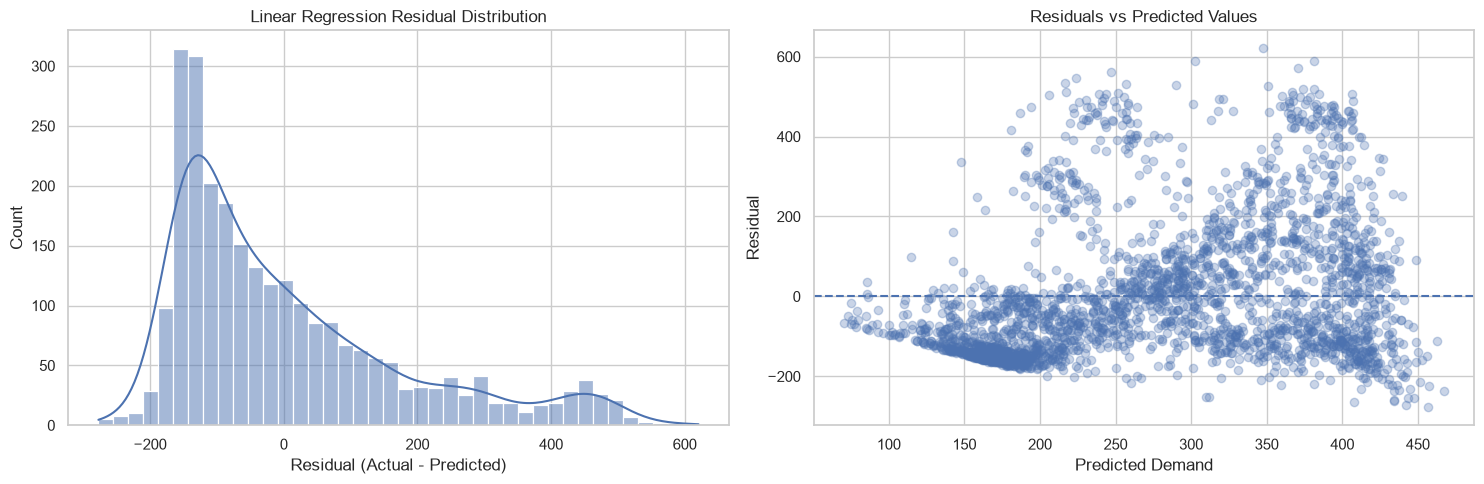

In [14]:
residuals_lr = y_val.values - y_pred_lr

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    residuals_lr,
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Linear Regression Residual Distribution")
axes[0].set_xlabel("Residual (Actual - Predicted)")

axes[1].scatter(
    y_pred_lr,
    residuals_lr,
    alpha=0.3
)

axes[1].axhline(
    0,
    linestyle="--"
)

axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted Demand")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

## 6. Random Forest Regression

Random Forest is introduced to capture nonlinear relationships and interactions between temporal, environmental, and demand-related features.

Unlike Linear Regression, Random Forest does not assume a linear relationship between predictors and the target variable.

This model is particularly relevant for bike-sharing demand forecasting because demand may respond differently to weather conditions, temperature, and time-related factors across different operational periods.

Categorical variables will be one-hot encoded, while numerical features will be retained without scaling.

The initial model configuration will use 300 decision trees, a minimum leaf size of two observations, and a fixed random seed to ensure reproducibility.

In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_features=0.8,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", rf_model)
    ]
)

random_forest_pipeline.fit(
    X_train,
    y_train
)

y_pred_rf = random_forest_pipeline.predict(X_val)

print("Random Forest training completed.")

print(f"Validation predictions: {len(y_pred_rf)}")
print(f"Minimum prediction: {y_pred_rf.min():.2f}")
print(f"Maximum prediction: {y_pred_rf.max():.2f}")
print(f"Negative predictions: {(y_pred_rf < 0).sum()}")

Random Forest training completed.
Validation predictions: 2607
Minimum prediction: 3.68
Maximum prediction: 815.03
Negative predictions: 0


In [16]:
rf_results = evaluate_model(
    y_val,
    y_pred_rf,
    "Random Forest"
)

model_comparison = pd.concat(
    [
        baseline_comparison,
        pd.DataFrame([
            lr_results,
            rf_results
        ])
    ],
    ignore_index=True
)

model_comparison = (
    model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(model_comparison.round(3))

,Model,MAE,RMSE,R2,WAPE (%)
0,Random Forest,51.962,79.263,0.874,18.489
1,Hourly-Weekly Average,127.046,168.459,0.431,45.205
2,Linear Regression,136.323,174.391,0.390,48.506
3,Global Mean,194.135,253.970,-0.294,69.077


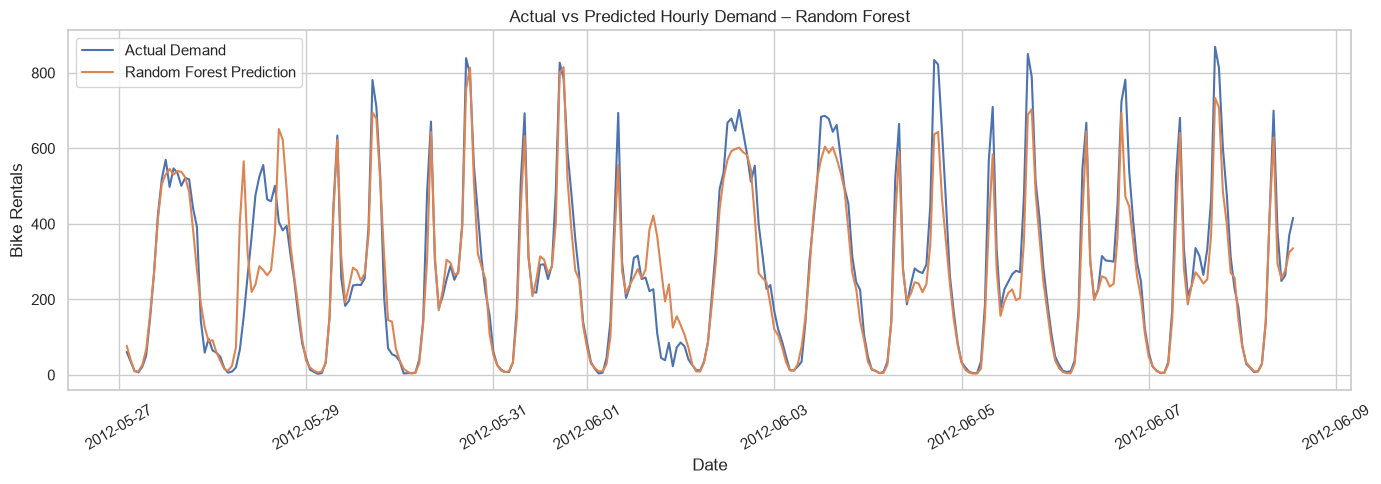

In [17]:
fig, ax = plt.subplots(figsize=(14, 5))

sample_size = min(300, len(y_val))

ax.plot(
    val_dates.iloc[:sample_size],
    y_val.iloc[:sample_size].values,
    label="Actual Demand",
    linewidth=1.5
)

ax.plot(
    val_dates.iloc[:sample_size],
    y_pred_rf[:sample_size],
    label="Random Forest Prediction",
    linewidth=1.5
)

ax.set_title("Actual vs Predicted Hourly Demand – Random Forest")
ax.set_xlabel("Date")
ax.set_ylabel("Bike Rentals")
ax.legend()

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

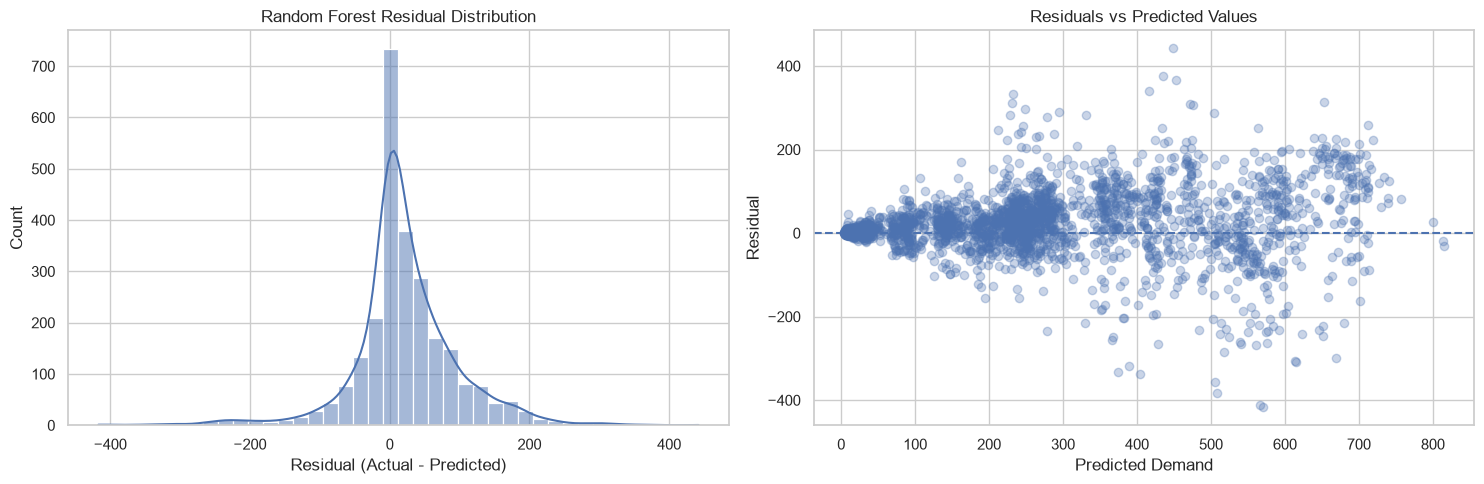

In [18]:
residuals_rf = y_val.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    residuals_rf,
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Random Forest Residual Distribution")
axes[0].set_xlabel("Residual (Actual - Predicted)")

axes[1].scatter(
    y_pred_rf,
    residuals_rf,
    alpha=0.3
)

axes[1].axhline(0, linestyle="--")

axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted Demand")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

,Feature,Importance Mean,Importance Std
0,hour_sin,106.465,1.770
1,hour_cos,98.895,1.410
2,weekday_sin,15.560,0.615
3,is_weekend,10.769,0.631
4,workingday,4.415,0.261
5,hum,3.633,0.212
6,weathersit,2.344,0.368
7,weekday_cos,1.417,0.294
8,atemp,0.571,0.074
9,season,0.213,0.055


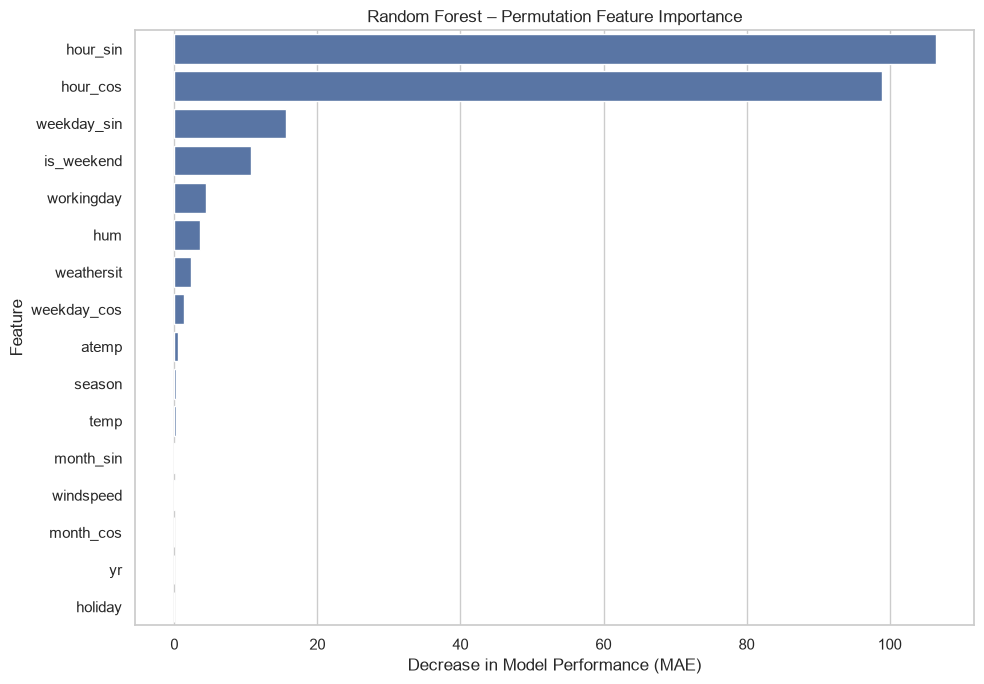

In [19]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    random_forest_pipeline,
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

feature_importance = (
    feature_importance
    .sort_values("Importance Mean", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(4))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance Mean",
    y="Feature"
)

plt.title("Random Forest – Permutation Feature Importance")
plt.xlabel("Decrease in Model Performance (MAE)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Random Forest Model Evaluation

The Random Forest model substantially outperformed all baseline models on the validation dataset.

- It achieved an MAE of 51.96, reducing the error by approximately 59.1% compared with the hourly-weekly average baseline.
- Its RMSE of 79.26 indicates a considerable reduction in larger prediction errors.
- The R² score of 0.874 suggests that the model explains a large proportion of the variation in hourly bike demand.
- The WAPE of 18.49% demonstrates a substantial improvement in overall demand estimation accuracy.

The permutation feature importance analysis revealed that cyclical hour features (`hour_sin` and `hour_cos`) are the strongest predictors. Weekly patterns, particularly `weekday_sin`, `is_weekend`, and `workingday`, also contribute to the predictions.

Weather-related variables, especially humidity and weather conditions, provide additional predictive information, although their contribution is smaller than that of temporal features.

Overall, the results suggest that bike-sharing demand is primarily driven by temporal patterns, while weather and calendar characteristics provide additional explanatory power. The Random Forest model is therefore selected as the leading candidate for further evaluation.

However, aggregate metrics alone do not reveal whether the model performs equally well during peak-demand and low-demand periods. Further residual analysis and demand-segment evaluation are required before finalizing the forecasting model.

In [20]:
validation_analysis = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": np.asarray(y_pred_rf)
})

validation_analysis["Absolute Error"] = (
    validation_analysis["Actual"] -
    validation_analysis["Predicted"]
).abs()

validation_analysis["Bias"] = (
    validation_analysis["Predicted"] -
    validation_analysis["Actual"]
)

bins = [0, 100, 300, 500, 700, np.inf]
labels = [
    "Very Low (0-100)",
    "Low (100-300)",
    "Medium (300-500)",
    "High (500-700)",
    "Very High (700+)"
]

validation_analysis["Demand Segment"] = pd.cut(
    validation_analysis["Actual"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

segment_results = (
    validation_analysis
    .groupby("Demand Segment", observed=False)
    .apply(lambda group: pd.Series({
        "Observations": len(group),
        "Avg Actual Demand": group["Actual"].mean(),
        "Avg Predicted Demand": group["Predicted"].mean(),
        "MAE": group["Absolute Error"].mean(),
        "RMSE": np.sqrt(
            np.mean(
                (group["Actual"] - group["Predicted"]) ** 2
            )
        ),
        "Bias": group["Bias"].mean(),
        "WAPE (%)": (
            group["Absolute Error"].sum() /
            group["Actual"].abs().sum() * 100
            if group["Actual"].abs().sum() != 0 else np.nan
        )
    }))
    .reset_index()
)

display(segment_results.round(3))

,Demand Segment,Observations,Avg Actual Demand,Avg Predicted Demand,MAE,RMSE,Bias,WAPE (%)
0,Very Low (0-100),704.000,31.847,35.667,12.872,31.590,3.820,40.417
1,Low (100-300),865.000,212.214,211.418,39.049,60.568,-0.796,18.401
2,Medium (300-500),593.000,395.288,365.616,75.952,91.992,-29.672,19.214
3,High (500-700),302.000,587.523,519.275,86.293,108.526,-68.248,14.688
4,Very High (700+),143.000,803.161,653.374,150.534,165.730,-149.787,18.743


In [21]:
validation_analysis["Underpredicted"] = (
    validation_analysis["Predicted"] <
    validation_analysis["Actual"]
)

validation_analysis["Overpredicted"] = (
    validation_analysis["Predicted"] >
    validation_analysis["Actual"]
)

direction_analysis = (
    validation_analysis
    .groupby("Demand Segment", observed=False)
    .apply(lambda group: pd.Series({
        "Observations": len(group),
        "Underprediction Count": group["Underpredicted"].sum(),
        "Underprediction (%)": (
            group["Underpredicted"].mean() * 100
        ),
        "Overprediction (%)": (
            group["Overpredicted"].mean() * 100
        ),
        "Mean Bias": group["Bias"].mean(),
        "90th Percentile Absolute Error": (
            group["Absolute Error"].quantile(0.90)
        )
    }))
    .reset_index()
)

display(direction_analysis.round(2))

,Demand Segment,Observations,Underprediction Count,Underprediction (%),Overprediction (%),Mean Bias,90th Percentile Absolute Error
0,Very Low (0-100),704.000,361.000,51.280,48.720,3.820,26.460
1,Low (100-300),865.000,542.000,62.660,37.340,-0.800,68.110
2,Medium (300-500),593.000,429.000,72.340,27.660,-29.670,136.420
3,High (500-700),302.000,232.000,76.820,23.180,-68.250,172.690
4,Very High (700+),143.000,140.000,97.900,2.100,-149.790,217.760


## 7. Two-Stage Demand Forecasting

### 7.1 High-Demand Expert Model Preparation

In [22]:
HIGH_DEMAND_THRESHOLD = 500
high_demand_mask = y_train >= HIGH_DEMAND_THRESHOLD

X_train_high = X_train.loc[high_demand_mask].copy()
y_train_high = y_train.loc[high_demand_mask].copy()

print("High-Demand Training Dataset")
print("-" * 40)
print(f"Threshold: {HIGH_DEMAND_THRESHOLD}")
print(f"Total training observations: {len(X_train)}")
print(f"High-demand observations: {len(X_train_high)}")
print(
    f"High-demand proportion: "
    f"{len(X_train_high) / len(X_train) * 100:.2f}%"
)

print(f"\nMinimum demand: {y_train_high.min()}")
print(f"Maximum demand: {y_train_high.max()}")
print(f"Average demand: {y_train_high.mean():.2f}")

High-Demand Training Dataset
----------------------------------------
Threshold: 500
Total training observations: 12165
High-demand observations: 495
High-demand proportion: 4.07%

Minimum demand: 500
Maximum demand: 957
Average demand: 598.51


In [23]:
from sklearn.ensemble import RandomForestRegressor

expert_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

high_demand_expert = Pipeline([
    ("preprocessor", expert_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        max_depth=8,
        min_samples_leaf=4,
        min_samples_split=8,
        random_state=42,
        n_jobs=-1
    ))
])

high_demand_expert.fit(X_train_high, y_train_high)
y_pred_expert = high_demand_expert.predict(X_val)

print(f"Training observations: {len(X_train_high)}")
print(f"Validation predictions: {len(y_pred_expert)}")
print(f"Minimum prediction: {y_pred_expert.min():.2f}")
print(f"Maximum prediction: {y_pred_expert.max():.2f}")
print(f"Average prediction: {y_pred_expert.mean():.2f}")

Training observations: 495
Validation predictions: 2607
Minimum prediction: 531.95
Maximum prediction: 774.01
Average prediction: 563.41


In [24]:
thresholds = [350, 400, 450, 500, 550, 600]

y_val_array = np.asarray(y_val)
high_actual_mask = y_val_array >= HIGH_DEMAND_THRESHOLD

threshold_results = []

for threshold in thresholds:
    use_expert = y_pred_rf >= threshold
    y_pred_hybrid = np.where(
        use_expert,
        y_pred_expert,
        y_pred_rf
    )

    overall = evaluate_model(
        y_val_array,
        y_pred_hybrid,
        f"Hybrid (Threshold={threshold})"
    )

    actual_high = y_val_array[high_actual_mask]
    predicted_high = y_pred_hybrid[high_actual_mask]

    high_mae = mean_absolute_error(
        actual_high, predicted_high
    )

    high_rmse = np.sqrt(
        mean_squared_error(actual_high, predicted_high)
    )

    high_bias = np.mean(predicted_high - actual_high)

    high_underprediction = np.mean(
        predicted_high < actual_high
    ) * 100

    threshold_results.append({
        "Threshold": threshold,
        "Expert Usage (%)": use_expert.mean() * 100,
        "Overall MAE": overall["MAE"],
        "Overall RMSE": overall["RMSE"],
        "Overall R2": overall["R2"],
        "Overall WAPE (%)": overall["WAPE (%)"],
        "High-Demand MAE": high_mae,
        "High-Demand RMSE": high_rmse,
        "High-Demand Bias": high_bias,
        "High-Demand Underprediction (%)": high_underprediction
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(3))

,Threshold,Expert Usage (%),Overall MAE,Overall RMSE,Overall R2,Overall WAPE (%),High-Demand MAE,High-Demand RMSE,High-Demand Bias,High-Demand Underprediction (%)
0,350,30.380,60.687,94.659,0.820,21.594,103.909,133.995,-83.000,73.556
1,400,24.281,56.132,87.044,0.848,19.973,107.857,136.898,-91.360,77.333
2,450,19.524,54.385,84.364,0.857,19.351,115.602,143.825,-105.169,83.111
3,500,15.995,54.935,85.240,0.854,19.547,124.729,150.753,-116.497,87.333
4,550,11.776,54.698,84.912,0.855,19.463,125.481,151.600,-120.283,89.778
5,600,6.674,54.723,84.925,0.855,19.472,123.970,150.388,-117.167,88.000


### 7.2 Classification-Based Demand Routing

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

y_train_high_label = (
    y_train >= HIGH_DEMAND_THRESHOLD
).astype(int)

gate_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

high_demand_classifier = Pipeline([
    ("preprocessor", gate_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

high_demand_classifier.fit(
    X_train,
    y_train_high_label
)

high_demand_probabilities = (
    high_demand_classifier.predict_proba(X_val)[:, 1]
)

print(f"Training observations: {len(X_train)}")
print(f"High-demand training observations: {y_train_high_label.sum()}")
print(
    f"High-demand probability range: "
    f"{high_demand_probabilities.min():.3f} - "
    f"{high_demand_probabilities.max():.3f}"
)
print(
    f"Average high-demand probability: "
    f"{high_demand_probabilities.mean():.3f}"
)
print("-" * 40)

probability_thresholds = [
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.50, 0.60
]

y_val_array = np.asarray(y_val)
high_actual_mask = y_val_array >= HIGH_DEMAND_THRESHOLD

classifier_gate_results = []

for threshold in probability_thresholds:

    use_expert = high_demand_probabilities >= threshold
    y_pred_gated = np.where(
        use_expert,
        y_pred_expert,
        y_pred_rf
    )
    actual_labels = high_actual_mask.astype(int)
    predicted_labels = use_expert.astype(int)

    overall = evaluate_model(
        y_val_array,
        y_pred_gated,
        f"Classifier Gate ({threshold})"
    )

    actual_high = y_val_array[high_actual_mask]
    predicted_high = y_pred_gated[high_actual_mask]

    classifier_gate_results.append({
        "Probability Threshold": threshold,
        "Expert Usage (%)": use_expert.mean() * 100,
        "Gate Precision (%)": precision_score(
            actual_labels,
            predicted_labels,
            zero_division=0
        ) * 100,
        "Gate Recall (%)": recall_score(
            actual_labels,
            predicted_labels,
            zero_division=0
        ) * 100,
        "Overall MAE": overall["MAE"],
        "Overall RMSE": overall["RMSE"],
        "High-Demand MAE": mean_absolute_error(
            actual_high,
            predicted_high
        ),
        "High-Demand Bias": np.mean(
            predicted_high - actual_high
        ),
        "High-Demand Underprediction (%)": np.mean(
            predicted_high < actual_high
        ) * 100
    })

classifier_gate_comparison = pd.DataFrame(
    classifier_gate_results
)

display(classifier_gate_comparison.round(3))

Training observations: 12165
High-demand training observations: 495
High-demand probability range: 0.034 - 0.980
Average high-demand probability: 0.298
----------------------------------------


,Probability Threshold,Expert Usage (%),Gate Precision (%),Gate Recall (%),Overall MAE,Overall RMSE,High-Demand MAE,High-Demand Bias,High-Demand Underprediction (%)
0,0.100,80.476,21.401,99.778,227.692,288.175,98.268,-76.067,71.778
1,0.150,65.631,25.658,97.556,172.433,237.022,101.101,-80.740,73.556
2,0.200,55.121,30.550,97.556,135.715,199.503,101.101,-80.740,73.556
3,0.250,40.621,41.454,97.556,90.542,145.953,101.101,-80.740,73.556
4,0.300,32.413,50.414,94.667,71.342,116.000,104.271,-86.687,76.000
5,0.350,29.459,53.776,91.778,66.519,106.541,107.038,-91.724,78.667
6,0.400,26.314,59.184,90.222,62.871,100.768,108.173,-94.608,80.222
7,0.500,20.330,72.642,85.556,54.801,85.525,110.543,-99.175,82.000
8,0.600,13.464,83.761,65.333,52.869,81.910,111.066,-101.538,84.444


In [26]:
soft_thresholds = [0.30, 0.40, 0.50, 0.60]

soft_gating_results = []

y_val_array = np.asarray(y_val)
high_actual_mask = y_val_array >= HIGH_DEMAND_THRESHOLD

for threshold in soft_thresholds:
    expert_weight = np.clip(
        (high_demand_probabilities - threshold) /
        (1 - threshold),
        0,
        1
    )

    y_pred_soft = (
        (1 - expert_weight) * y_pred_rf +
        expert_weight * y_pred_expert
    )

    overall = evaluate_model(
        y_val_array,
        y_pred_soft,
        f"Soft Gating ({threshold})"
    )

    actual_high = y_val_array[high_actual_mask]
    predicted_high = y_pred_soft[high_actual_mask]

    soft_gating_results.append({
        "Probability Threshold": threshold,
        "Average Expert Weight (%)": expert_weight.mean() * 100,
        "Overall MAE": overall["MAE"],
        "Overall RMSE": overall["RMSE"],
        "Overall R2": overall["R2"],
        "High-Demand MAE": mean_absolute_error(
            actual_high,
            predicted_high
        ),
        "High-Demand RMSE": np.sqrt(
            mean_squared_error(actual_high, predicted_high)
        ),
        "High-Demand Bias": np.mean(
            predicted_high - actual_high
        ),
        "High-Demand Underprediction (%)": np.mean(
            predicted_high < actual_high
        ) * 100
    })

soft_gating_comparison = pd.DataFrame(soft_gating_results)

display(soft_gating_comparison.round(3))

,Probability Threshold,Average Expert Weight (%),Overall MAE,Overall RMSE,Overall R2,High-Demand MAE,High-Demand RMSE,High-Demand Bias,High-Demand Underprediction (%)
0,0.300,13.544,54.050,82.873,0.862,111.437,137.512,-103.044,85.556
1,0.400,10.911,53.591,82.459,0.864,113.331,139.093,-104.936,86.444
2,0.500,8.441,53.388,82.398,0.864,114.996,140.449,-106.481,86.444
3,0.600,6.146,53.664,82.846,0.862,116.701,141.881,-107.946,86.667


In [27]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

expert_thresholds = [350, 400, 450]
gate_threshold = 0.60
high_demand_mask = np.asarray(y_val) >= 500

expert_comparison = []

for expert_threshold in expert_thresholds:
    expert_mask = np.asarray(y_train) >= expert_threshold
    X_train_expert = X_train.loc[expert_mask]
    y_train_expert = y_train.loc[expert_mask]
    expert_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_features=0.8,
            max_depth=8,
            min_samples_leaf=4,
            min_samples_split=8,
            random_state=42,
            n_jobs=-1
        ))
    ])

    expert_model.fit(X_train_expert, y_train_expert)
    expert_predictions = expert_model.predict(X_val)
    use_expert = high_demand_probabilities >= gate_threshold

    hybrid_predictions = np.where(
        use_expert,
        expert_predictions,
        y_pred_rf
    )
    overall_mae = mean_absolute_error(y_val, hybrid_predictions)
    overall_rmse = np.sqrt(mean_squared_error(y_val, hybrid_predictions))
    overall_r2 = r2_score(y_val, hybrid_predictions)
    actual_high = np.asarray(y_val)[high_demand_mask]
    predicted_high = hybrid_predictions[high_demand_mask]
    high_mae = mean_absolute_error(actual_high, predicted_high)
    high_rmse = np.sqrt(mean_squared_error(actual_high, predicted_high))
    high_bias = np.mean(predicted_high - actual_high)

    high_underprediction = (
        np.mean(predicted_high < actual_high) * 100
    )

    expert_comparison.append({
        "Expert Training Threshold": expert_threshold,
        "Training Observations": expert_mask.sum(),
        "Expert Usage (%)": use_expert.mean() * 100,
        "Overall MAE": overall_mae,
        "Overall RMSE": overall_rmse,
        "Overall R2": overall_r2,
        "High-Demand MAE": high_mae,
        "High-Demand RMSE": high_rmse,
        "High-Demand Bias": high_bias,
        "High-Demand Underprediction (%)": high_underprediction
    })

expert_comparison = pd.DataFrame(expert_comparison)

display(
    expert_comparison.round(3)
    .sort_values("Overall MAE")
    .reset_index(drop=True)
)

,Expert Training Threshold,Training Observations,Expert Usage (%),Overall MAE,Overall RMSE,Overall R2,High-Demand MAE,High-Demand RMSE,High-Demand Bias,High-Demand Underprediction (%)
0,350,1501,13.464,51.224,77.395,0.880,101.501,120.970,-88.684,84.000
1,450,726,13.464,51.794,78.909,0.875,104.638,127.226,-95.875,84.000
2,400,1055,13.464,53.524,82.050,0.865,118.811,141.281,-114.197,90.667


In [28]:
X_train_val = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_val = pd.concat(
    [y_train, y_val],
    axis=0
)

print("Final Training Dataset")
print("-" * 40)
print(f"Observations: {len(X_train_val)}")
print(f"Training period: {train_dates.min()} - {train_dates.max()}")
print(f"Validation period: {val_dates.min()} - {val_dates.max()}")
print(f"Combined dataset shape: {X_train_val.shape}")
print(f"Reserved test observations: {len(X_test)}")


from sklearn.base import clone
final_rf_model = clone(random_forest_pipeline)
final_rf_model.fit(
    X_train_val,
    y_train_val
)
final_classifier = clone(high_demand_classifier)
y_train_val_high_label = (
    y_train_val >= HIGH_DEMAND_THRESHOLD
).astype(int)

final_classifier.fit(
    X_train_val,
    y_train_val_high_label
)

FINAL_EXPERT_THRESHOLD = 350
final_expert_mask = (
    y_train_val >= FINAL_EXPERT_THRESHOLD
)
X_train_val_expert = X_train_val.loc[
    final_expert_mask
]
y_train_val_expert = y_train_val.loc[
    final_expert_mask
]
final_expert_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        max_depth=8,
        min_samples_leaf=4,
        min_samples_split=8,
        random_state=42,
        n_jobs=-1
    ))
])

final_expert_model.fit(
    X_train_val_expert,
    y_train_val_expert
)

print(f"Training observations: {len(X_train_val)}")
print(f"Expert training observations: {len(X_train_val_expert)}")
print(f"Expert threshold: {FINAL_EXPERT_THRESHOLD}")
print(f"Classifier threshold: 0.60")

y_test_pred_rf = final_rf_model.predict(X_test)
test_high_demand_probabilities = (
    final_classifier.predict_proba(X_test)[:, 1]
)

y_test_pred_expert = final_expert_model.predict(X_test)
FINAL_GATE_THRESHOLD = 0.60
test_use_expert = (
    test_high_demand_probabilities >= FINAL_GATE_THRESHOLD
)

y_test_pred_hybrid = np.where(
    test_use_expert,
    y_test_pred_expert,
    y_test_pred_rf
)
print("-" * 40)
print("Test predictions generated.")
print(f"Test observations: {len(X_test)}")
print(f"Expert usage: {test_use_expert.mean() * 100:.2f}%")


Final Training Dataset
----------------------------------------
Observations: 14772
Training period: 2011-01-01 00:00:00 - 2012-05-27 01:00:00
Validation period: 2012-05-27 02:00:00 - 2012-09-12 16:00:00
Combined dataset shape: (14772, 16)
Reserved test observations: 2607
Training observations: 14772
Expert training observations: 2359
Expert threshold: 350
Classifier threshold: 0.60
----------------------------------------
Test predictions generated.
Test observations: 2607
Expert usage: 11.28%


In [29]:
test_results = []

test_results.append(
    evaluate_model(
        y_test,
        y_test_pred_rf,
        "Random Forest"
    )
)

test_results.append(
    evaluate_model(
        y_test,
        y_test_pred_hybrid,
        "Final Hybrid Model"
    )
)

test_comparison = (
    pd.DataFrame(test_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(test_comparison.round(3))

,Model,MAE,RMSE,R2,WAPE (%)
0,Random Forest,49.119,73.268,0.884,20.842
1,Final Hybrid Model,49.818,74.610,0.880,21.138


# Lag Feature Tree Models

In [41]:
lag_data = df_model.copy()

lag_data["timestamp"] = (
    pd.to_datetime(lag_data["dteday"])
    + pd.to_timedelta(lag_data["hr"], unit="h")
)

lag_data = lag_data.sort_values("timestamp").reset_index(drop=True)

assert lag_data["timestamp"].is_unique, "Duplicate timestamps detected."
demand_by_timestamp = lag_data.set_index("timestamp")["cnt"]

lag_data["cnt_lag_1"] = (
    lag_data["timestamp"] - pd.Timedelta(hours=1)
).map(demand_by_timestamp)

lag_data["cnt_lag_24"] = (
    lag_data["timestamp"] - pd.Timedelta(hours=24)
).map(demand_by_timestamp)

print("Lag Feature Availability")
print("-" * 40)
print(f"Total observations: {len(lag_data)}")
print(f"Missing cnt_lag_1: {lag_data['cnt_lag_1'].isna().sum()}")
print(f"Missing cnt_lag_24: {lag_data['cnt_lag_24'].isna().sum()}")

lag_data = lag_data.dropna(
    subset=["cnt_lag_1", "cnt_lag_24"]
).copy()

print(f"Observations after lag creation: {len(lag_data)}")

display(
    lag_data[
        ["timestamp", "cnt", "cnt_lag_1", "cnt_lag_24"]
    ].head(10)
)

lag_features = [
    "cnt_lag_1",
    "cnt_lag_24"
]

updated_feature_columns = feature_columns + lag_features
updated_numerical_features = numerical_features + lag_features
X_lag = lag_data[updated_feature_columns].copy()
y_lag = lag_data[target].copy()
timestamps_lag = lag_data["timestamp"].copy()
train_ratio = 0.70
validation_ratio = 0.15

n_lag = len(lag_data)
train_end_l = int(n_lag * train_ratio)
validation_end_l = int(n_lag * (train_ratio + validation_ratio))
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            updated_numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)
X_train_lag = X_lag.iloc[:train_end_l].copy()
X_val_lag = X_lag.iloc[train_end_l:validation_end_l].copy()
X_test_lag = X_lag.iloc[validation_end_l:].copy()

y_train_lag = y_lag.iloc[:train_end_l].copy()
y_val_lag = y_lag.iloc[train_end_l:validation_end_l].copy()
y_test_lag = y_lag.iloc[validation_end_l:].copy()

train_dates_lag = timestamps_lag.iloc[:train_end_l]
val_dates_lag = timestamps_lag.iloc[train_end_l:validation_end_l]
test_dates_lag = timestamps_lag.iloc[validation_end_l:]

print("Updated temporal split")
print("-" * 40)
print(f"Train: {train_dates_lag.min()} to {train_dates_lag.max()}")
print(f"Validation: {val_dates_lag.min()} to {val_dates_lag.max()}")
print(f"Test: {test_dates_lag.min()} to {test_dates_lag.max()}")

print("\nDataset sizes:")
print(f"Train: {len(X_train_lag)}")
print(f"Validation: {len(X_val_lag)}")
print(f"Test: {len(X_test_lag)}")

assert train_dates_lag.max() < val_dates_lag.min()
assert val_dates_lag.max() < test_dates_lag.min()

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            updated_numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
import importlib.util

models = {}

models["Random Forest"] = RandomForestRegressor(
    n_estimators=300,
    max_features=0.8,
    max_depth=8,
    min_samples_leaf=4,
    min_samples_split=8,
    random_state=42,
    n_jobs=-1
)

if importlib.util.find_spec("xgboost") is not None:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

if importlib.util.find_spec("lightgbm") is not None:
    from lightgbm import LGBMRegressor

    models["LightGBM"] = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=20,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=2,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

if importlib.util.find_spec("catboost") is not None:
    from catboost import CatBoostRegressor

    models["CatBoost"] = CatBoostRegressor(
        iterations=500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

print("Available models:")
for model_name in models:
    print("-", model_name)

model_pipelines = {}
validation_predictions = {}
tree_model_results = []

for model_name, model in models.items():

    print(f"Training {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", clone(model))
    ])
    
    pipeline.fit(X_train_lag, y_train_lag)
    
    predictions = pipeline.predict(X_val_lag)

    model_pipelines[model_name] = pipeline
    validation_predictions[model_name] = predictions

    tree_model_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_val_lag, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_lag, predictions)
        ),
        "R2": r2_score(y_val_lag, predictions),
        "WAPE (%)": (
            np.sum(np.abs(y_val_lag - predictions))
            / np.sum(np.abs(y_val_lag))
        ) * 100
    })

print("All models trained successfully.")

validation_results = (
    pd.DataFrame(tree_model_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(validation_results.round(3))

Lag Feature Availability
----------------------------------------
Total observations: 17379
Missing cnt_lag_1: 76
Missing cnt_lag_24: 160
Observations after lag creation: 17158


,timestamp,cnt,cnt_lag_1,cnt_lag_24
24,2011-01-02 00:00:00,17,39.000,16.000
25,2011-01-02 01:00:00,17,17.000,40.000
26,2011-01-02 02:00:00,9,17.000,32.000
27,2011-01-02 03:00:00,6,9.000,13.000
28,2011-01-02 04:00:00,3,6.000,1.000
30,2011-01-02 07:00:00,1,2.000,3.000
31,2011-01-02 08:00:00,8,1.000,8.000
32,2011-01-02 09:00:00,20,8.000,14.000
33,2011-01-02 10:00:00,53,20.000,36.000
34,2011-01-02 11:00:00,70,53.000,56.000


Updated temporal split
----------------------------------------
Train: 2011-01-02 00:00:00 to 2012-05-28 12:00:00
Validation: 2012-05-28 13:00:00 to 2012-09-12 18:00:00
Test: 2012-09-12 19:00:00 to 2012-12-31 23:00:00

Dataset sizes:
Train: 12010
Validation: 2574
Test: 2574
Available models:
- Random Forest
- XGBoost
Training Random Forest...
Training XGBoost...
All models trained successfully.


,Model,MAE,RMSE,R2,WAPE (%)
0,XGBoost,34.712,53.204,0.944,12.305
1,Random Forest,42.213,64.089,0.918,14.964


In [42]:
X_train_val_lag = pd.concat(
    [X_train_lag, X_val_lag],
    axis=0
)

y_train_val_lag = pd.concat(
    [y_train_lag, y_val_lag],
    axis=0
)

final_lag_results = []

for model_name in validation_results["Model"]:

    final_pipeline = Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", clone(models[model_name]))
    ])

    final_pipeline.fit(
        X_train_val_lag,
        y_train_val_lag
    )

    test_predictions = final_pipeline.predict(
        X_test_lag
    )

    result = evaluate_model(
        y_test_lag,
        test_predictions,
        model_name
    )

    final_lag_results.append(result)

final_lag_comparison = (
    pd.DataFrame(final_lag_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(final_lag_comparison.round(3))

,Model,MAE,RMSE,R2,WAPE (%)
0,XGBoost,26.399,41.851,0.962,11.151
1,Random Forest,31.439,50.486,0.945,13.281


In [43]:
X_lagless = lag_data[feature_columns].copy()

X_train_lagless = X_lagless.iloc[:train_end_l].copy()
X_val_lagless = X_lagless.iloc[train_end_l:validation_end_l].copy()
X_test_lagless = X_lagless.iloc[validation_end_l:].copy()

X_train_val_lagless = pd.concat(
    [X_train_lagless, X_val_lagless],
    axis=0
)

tree_preprocessor_lagless = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

ablation_results = []

for model_name in validation_results["Model"]:

    model_with_lags = Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", clone(models[model_name]))
    ])

    model_with_lags.fit(
        X_train_val_lag,
        y_train_val_lag
    )

    pred_with_lags = model_with_lags.predict(X_test_lag)

    model_without_lags = Pipeline([
        ("preprocessor", clone(tree_preprocessor_lagless)),
        ("model", clone(models[model_name]))
    ])

    model_without_lags.fit(
        X_train_val_lagless,
        y_train_val_lag
    )

    pred_without_lags = model_without_lags.predict(X_test_lagless)

    for feature_setup, predictions in [
        ("With Lag Features", pred_with_lags),
        ("Without Lag Features", pred_without_lags)
    ]:

        ablation_results.append({
            "Model": model_name,
            "Feature Setup": feature_setup,
            "MAE": mean_absolute_error(y_test_lag, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test_lag, predictions)
            ),
            "R2": r2_score(y_test_lag, predictions),
            "WAPE (%)": (
                np.sum(np.abs(y_test_lag - predictions))
                / np.sum(np.abs(y_test_lag))
            ) * 100
        })

ablation_comparison = (
    pd.DataFrame(ablation_results)
    .sort_values(["Model", "Feature Setup"])
    .reset_index(drop=True)
)

display(ablation_comparison.round(3))

,Model,Feature Setup,MAE,RMSE,R2,WAPE (%)
0,Random Forest,With Lag Features,31.439,50.486,0.945,13.281
1,Random Forest,Without Lag Features,58.824,86.024,0.839,24.849
2,XGBoost,With Lag Features,26.399,41.851,0.962,11.151
3,XGBoost,Without Lag Features,43.665,65.746,0.906,18.445


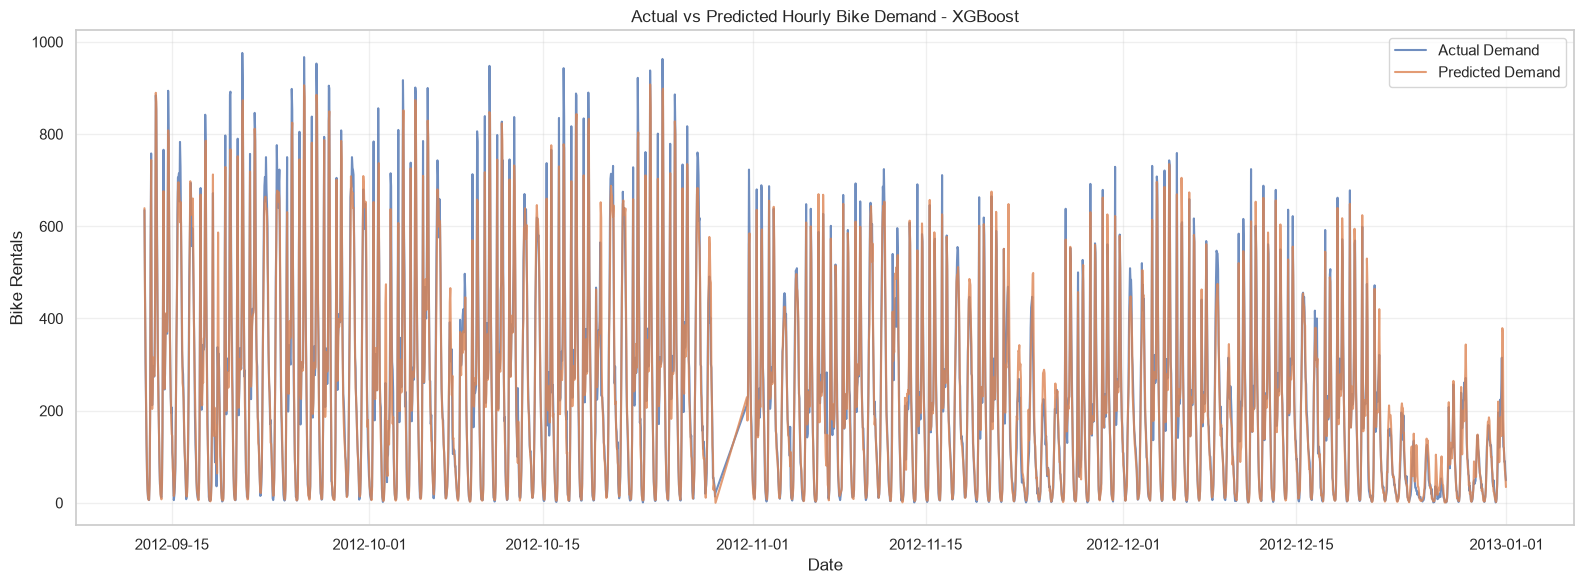

In [44]:
best_model_name = "XGBoost"

best_lag_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("model", clone(models[best_model_name]))
])

best_lag_pipeline.fit(
    X_train_val_lag,
    y_train_val_lag
)

best_test_predictions = best_lag_pipeline.predict(X_test_lag)

test_results = lag_data.loc[
    X_test_lag.index,
    ["timestamp", "hr", "weekday", "cnt"]
].copy()

test_results["predicted_cnt"] = best_test_predictions
test_results["residual"] = (
    test_results["cnt"] - test_results["predicted_cnt"]
)

test_results["absolute_error"] = (
    test_results["residual"].abs()
)

plt.figure(figsize=(16, 6))

plt.plot(
    test_results["timestamp"],
    test_results["cnt"],
    label="Actual Demand",
    alpha=0.8
)

plt.plot(
    test_results["timestamp"],
    test_results["predicted_cnt"],
    label="Predicted Demand",
    alpha=0.8
)

plt.title("Actual vs Predicted Hourly Bike Demand - XGBoost")
plt.xlabel("Date")
plt.ylabel("Bike Rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,hr,observation_count,actual_demand,predicted_demand,MAE
0,0,108,65.370,62.690,16.000
1,1,107,42.210,41.520,9.560
2,2,107,26.820,27.940,6.640
3,3,101,13.530,15.950,5.250
4,4,103,8.310,8.470,3.500
5,5,106,27.820,23.920,7.650
6,6,107,95.000,95.950,10.840
7,7,107,271.250,268.030,32.740
8,8,107,471.950,444.160,48.540
9,9,107,281.790,268.820,29.500


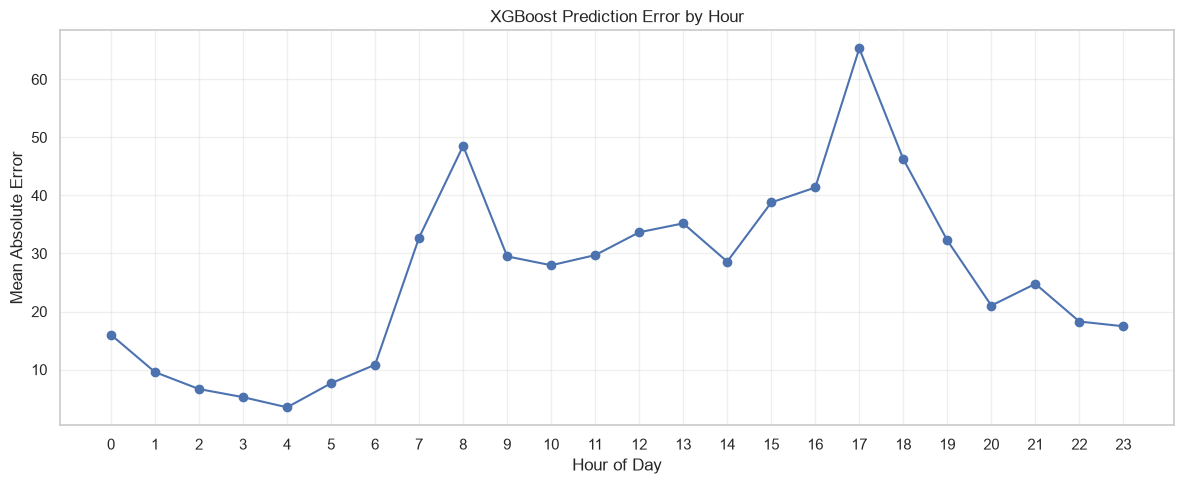

In [45]:
hourly_error = (
    test_results
    .groupby("hr")
    .agg(
        observation_count=("cnt", "count"),
        actual_demand=("cnt", "mean"),
        predicted_demand=("predicted_cnt", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

display(hourly_error.round(2))

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_error["hr"],
    hourly_error["MAE"],
    marker="o"
)

plt.title("XGBoost Prediction Error by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
test_results["demand_level"] = pd.cut(
    test_results["cnt"],
    bins=[-1, 100, 300, 500, 700, np.inf],
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

demand_error = (
    test_results
    .groupby("demand_level", observed=False)
    .agg(
        observation_count=("cnt", "count"),
        average_actual=("cnt", "mean"),
        average_predicted=("predicted_cnt", "mean"),
        MAE=("absolute_error", "mean"),
        average_bias=("residual", "mean")
    )
    .reset_index()
)

display(demand_error.round(2))

,demand_level,observation_count,average_actual,average_predicted,MAE,average_bias
0,Very Low,868,32.900,36.880,10.240,-3.980
1,Low,898,196.360,196.890,26.300,-0.530
2,Medium,471,385.020,375.350,38.550,9.670
3,High,223,591.800,577.170,41.500,14.630
4,Very High,114,799.450,734.410,70.470,65.030


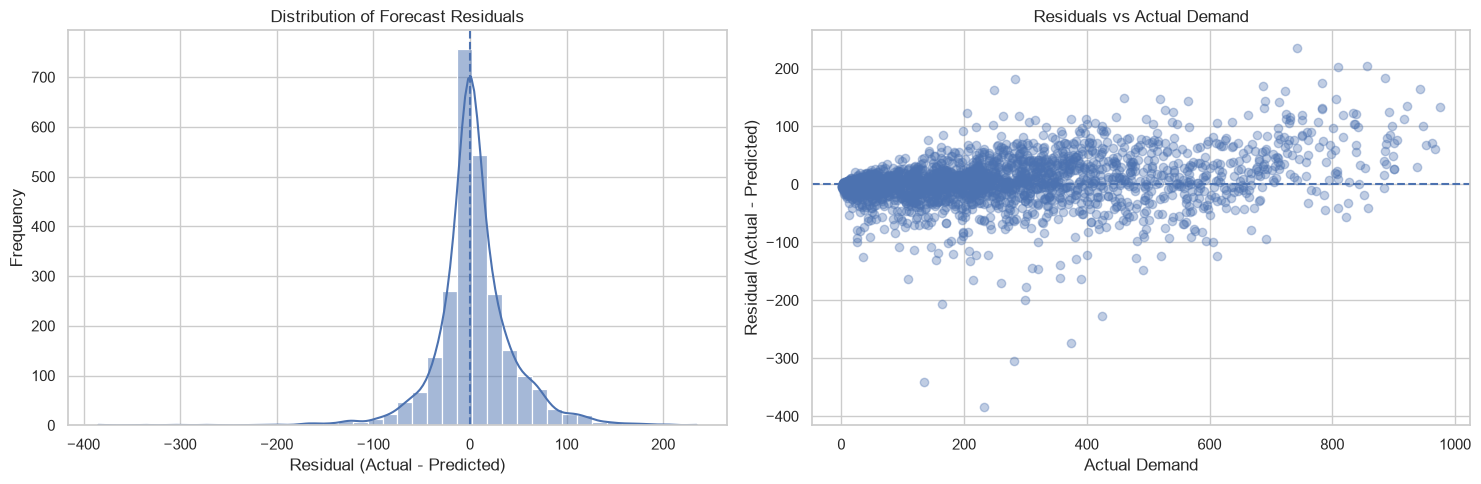

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    test_results["residual"],
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(0, linestyle="--")
axes[0].set_title("Distribution of Forecast Residuals")
axes[0].set_xlabel("Residual (Actual - Predicted)")
axes[0].set_ylabel("Frequency")
axes[1].scatter(
    test_results["cnt"],
    test_results["residual"],
    alpha=0.35
)

axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Actual Demand")
axes[1].set_xlabel("Actual Demand")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

## Forecasting Results and Key Findings

### Model Performance

The lag-based XGBoost model achieved the best forecasting performance on the test dataset:

- MAE: 26.40
- RMSE: 41.85
- R²: 0.962
- WAPE: 11.15%

The model outperformed the Random Forest model across all evaluation metrics.

### Contribution of Lag Features

The ablation analysis demonstrated the importance of historical demand information.

For XGBoost, incorporating the previous-hour and previous-day demand features reduced:

- MAE from 43.67 to 26.40
- RMSE from 65.75 to 41.85
- WAPE from 18.45% to 11.15%

This confirms that temporal demand dependencies provide substantial predictive value.

### Forecast Error Analysis

The model achieved relatively low errors across low and medium demand segments. However, prediction errors increased during very high-demand periods.
In particular, the model underestimated average demand in the Very High demand segment by approximately 65 rentals.
This suggests that additional attention may be required when forecasting peak demand, especially in operational planning scenarios.

### Forecasting Assumptions and Limitations

The lag-based forecasting approach assumes a rolling one-step-ahead prediction setting, where actual demand observations from preceding hours are available when generating each forecast.
The results should therefore not be interpreted as the performance of a fixed-origin multi-step forecasting model.
Additionally, 221 observations were excluded because the required historical lag values were unavailable due to missing timestamps. 

### Conclusion

The analysis demonstrates that historical demand information significantly improves hourly bike-sharing demand forecasts. 
The XGBoost model with lag features provides the strongest predictive performance among the evaluated models. Nevertheless, its tendency to underestimate very high demand levels should be considered when using forecasts for capacity allocation and operational planning.